In [4]:
#khởi tạo và nạp train
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.preprocess import load_split

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

train = load_split("train")  # EDA chỉ dùng train
train.shape

(709013, 8)

count    27662.000000
mean        24.266177
std         38.908502
min          1.000000
25%          6.000000
50%         15.000000
75%         28.000000
max        673.000000
Name: StockCode, dtype: float64
Tỷ lệ hóa đơn chỉ có 1 sản phẩm: 0.085


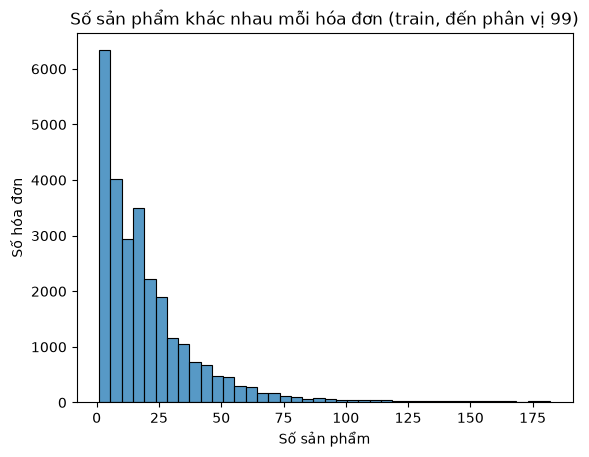

In [5]:
#giỏ hàng có bao nhiêu sản phẩm?
basket = train.groupby("Invoice")["StockCode"].nunique()
print(basket.describe())
print("Tỷ lệ hóa đơn chỉ có 1 sản phẩm:", round((basket == 1).mean(), 3))

fig, ax = plt.subplots()
sns.histplot(basket[basket <= basket.quantile(0.99)], bins=40, ax=ax)
ax.set(title="Số sản phẩm khác nhau mỗi hóa đơn (train, đến phân vị 99)",
       xlabel="Số sản phẩm", ylabel="Số hóa đơn")
fig.savefig(FIG / "eda_basket_size.png", dpi=150, bbox_inches="tight")

count    4426.000000
mean      151.660868
std       247.123597
min         1.000000
25%        17.000000
50%        63.000000
75%       176.750000
max      4261.000000
Name: count, dtype: float64
ngưỡng  2: giữ  4280 / 4426 sản phẩm, giữ 100.0% số cặp (hóa đơn, sản phẩm)
ngưỡng  5: giữ  4018 / 4426 sản phẩm, giữ 99.9% số cặp (hóa đơn, sản phẩm)
ngưỡng 10: giữ  3704 / 4426 sản phẩm, giữ 99.5% số cặp (hóa đơn, sản phẩm)
ngưỡng 20: giữ  3235 / 4426 sản phẩm, giữ 98.5% số cặp (hóa đơn, sản phẩm)
ngưỡng 50: giữ  2451 / 4426 sản phẩm, giữ 94.7% số cặp (hóa đơn, sản phẩm)


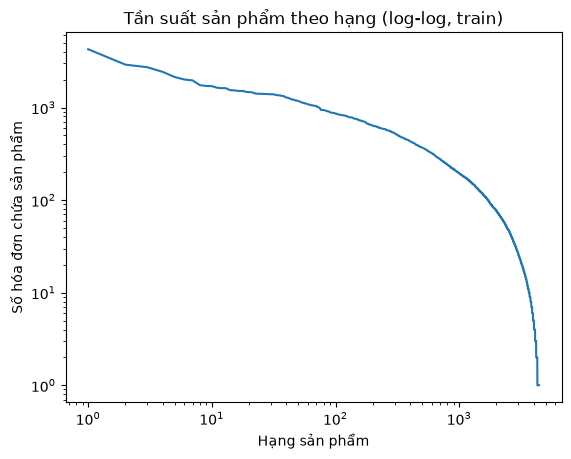

In [6]:
#tần suất sản phẩm (đuôi dài)
freq = train.drop_duplicates(["Invoice", "StockCode"])["StockCode"].value_counts()
print(freq.describe())

for t in (2, 5, 10, 20, 50):
    keep = freq >= t
    print(f"ngưỡng {t:>2}: giữ {keep.sum():>5} / {len(freq)} sản phẩm, "
          f"giữ {freq[keep].sum() / freq.sum():.1%} số cặp (hóa đơn, sản phẩm)")

fig, ax = plt.subplots()
ax.loglog(range(1, len(freq) + 1), freq.values)
ax.set(title="Tần suất sản phẩm theo hạng (log-log, train)",
       xlabel="Hạng sản phẩm", ylabel="Số hóa đơn chứa sản phẩm")
fig.savefig(FIG / "eda_item_frequency.png", dpi=150, bbox_inches="tight")

In [7]:
#top 20 sản phẩm phổ biến và tên hiển thị
desc = train.groupby("StockCode")["Description"].agg(lambda s: s.mode().iloc[0])
n_multi = (train.groupby("StockCode")["Description"].nunique() > 1).sum()
print(f"{n_multi} mã có hơn 1 mô tả khác nhau")

top = freq.head(20).rename("so_hoa_don").to_frame().join(desc)
top["ty_le_hoa_don"] = (top["so_hoa_don"] / train["Invoice"].nunique()).round(3)
top

516 mã có hơn 1 mô tả khác nhau


,so_hoa_don,Description,ty_le_hoa_don
StockCode,,,
85123A,4261,WHITE HANGING HEART T-LIGHT HOLDER,0.154
22423,2906,REGENCY CAKESTAND 3 TIER,0.105
85099B,2727,JUMBO BAG RED RETROSPOT,0.099
21212,2429,PACK OF 72 RETRO SPOT CAKE CASES,0.088
20725,2137,LUNCH BAG RED SPOTTY,0.077
21232,2007,STRAWBERRY CERAMIC TRINKET BOX,0.073
84879,1960,ASSORTED COLOUR BIRD ORNAMENT,0.071
47566,1745,PARTY BUNTING,0.063
84991,1710,60 TEATIME FAIRY CAKE CASES,0.062


In [8]:
#Customer ID bị thiếu bao nhiêu?
print("Tỷ lệ dòng thiếu Customer ID:", round(train["Customer ID"].isna().mean(), 3))
print("Tỷ lệ hóa đơn có Customer ID:",
      round(train.groupby("Invoice")["Customer ID"].first().notna().mean(), 3))
print("Số khách hàng:", train["Customer ID"].nunique())

with_c = train.dropna(subset=["Customer ID"])
print("Số sản phẩm còn lại nếu chỉ dùng dòng có khách:",
      with_c["StockCode"].nunique(), "/", train["StockCode"].nunique())

Tỷ lệ dòng thiếu Customer ID: 0.226
Tỷ lệ hóa đơn có Customer ID: 0.919
Số khách hàng: 4900
Số sản phẩm còn lại nếu chỉ dùng dòng có khách: 4223 / 4426


Country
United Kingdom    0.926
EIRE              0.017
Germany           0.015
France            0.012
Netherlands       0.005
Name: proportion, dtype: float64


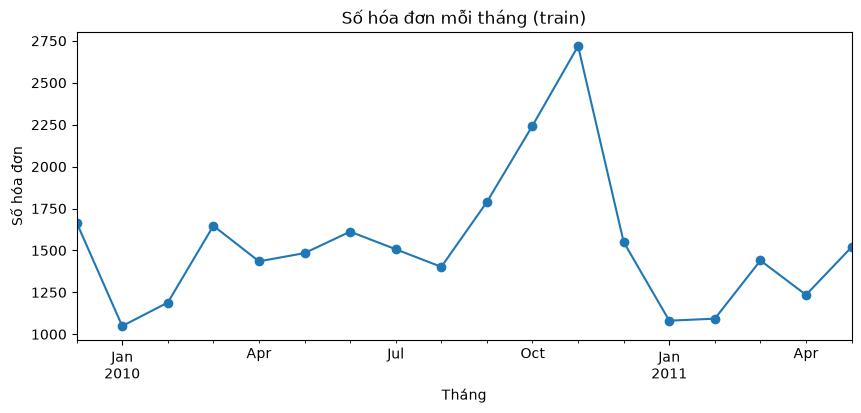

In [9]:
#quốc gia và theo thời gian
print(train["Country"].value_counts(normalize=True).head(5).round(3))

monthly = train.groupby(train["InvoiceDate"].dt.to_period("M"))["Invoice"].nunique()
fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(ax=ax, marker="o")
ax.set(title="Số hóa đơn mỗi tháng (train)", xlabel="Tháng", ylabel="Số hóa đơn")
fig.savefig(FIG / "eda_monthly_invoices.png", dpi=150, bbox_inches="tight")

In [10]:
#sản phẩm ở val mà train chưa từng thấy
val = load_split("val")  # chỉ val, không đụng test
pairs = val.drop_duplicates(["Invoice", "StockCode"])
unseen = ~pairs["StockCode"].isin(set(train["StockCode"]))
print("Tỷ lệ cặp (hóa đơn, sản phẩm) ở val có sản phẩm chưa thấy ở train:",
      round(unseen.mean(), 3))

Tỷ lệ cặp (hóa đơn, sản phẩm) ở val có sản phẩm chưa thấy ở train: 0.103
